# Problem Statement :    Uber Data Analysis

## Context
 Uber Technologies, Inc. is an American multinational transportation network company based in San Francisco and has operations in approximately 72 countries and 10,500 cities. In the fourth quarter of 2021, Uber had 118 million monthly active users worldwide and generated an average of 19 million trips per day.

Ridesharing is a very volatile market and demand fluctuates wildly with time, place, weather, local events, etc. The key to being successful in this business is to be able to detect patterns in these fluctuations and cater to demand at any given time.

As a newly hired Data Scientist in Uber's New York Office, you have been given the task of extracting insights from data that will help the business better understand the demand profile and take appropriate actions to drive better outcomes for the business. Your goal is to identify good insights that are potentially actionable, i.e., the business can do something with it.
## Objective
To extract actionable insights around demand patterns across various factors.

## Data Dictionary

**The data contains information about the weather, location, and pickups.**

| Column | Description |
| --- | --- |
| `pickup_dt` | Date and time of the pick-up |
| `borough` | NYC's borough |
| `pickups` | Number of pickups for the period |
| `spd` | Wind speed in miles/hour |
| `vsb` | Visibility in miles to the nearest tenth |
| `temp` | Temperature in Fahrenheit |
| `dewp` | Dew point in Fahrenheit |
| `slp` | Sea level pressure |
| `pcp01` | 1-hour liquid precipitation |
| `pcp06` | 6-hour liquid precipitation |
| `pcp24` | 24-hour liquid precipitation |
| `sd` | Snow depth in inches |
| `hday` | Holiday (Y) or not (N) |

## Questions to explore
1. What are the different variables that influence pickups?

2. Which factor affects the pickups the most? What could be plausible reasons for that?

3. What are your recommendations to Uber management to capitalize on fluctuating demand?


## Guidelines
1. Perform univariate analysis on the data to better understand the variables at your disposal.

2. Perform bivariate analysis to better understand the relationships between different variables.

3. Create visualizations to explore data and extract the insights.

In [1]:
#load necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
from pathlib import Path

# Reads Uber.csv from the repo's data/ folder; falls back to GitHub if run on Colab without the file
RAW = "https://raw.githubusercontent.com/Bilal-Butt/Uber-Data-Analysis/main/data/Uber.csv"
local = next((p / "Uber.csv" for p in (Path("../data"), Path("data"), Path(".")) if (p / "Uber.csv").exists()), None)

# read the original data
data = pd.read_csv(local if local else RAW)
# make a copy of original data so it remains untouched
df = data.copy()
print("number of rows and columns in the data:", df.shape)

number of rows and columns in the data: (29101, 13)


In [3]:
df

,pickup_dt,borough,pickups,spd,vsb,temp,dewp,slp,pcp01,pcp06,pcp24,sd,hday
0,2015-01-01 01:00:00,Bronx,152,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y
1,2015-01-01 01:00:00,Brooklyn,1519,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y
2,2015-01-01 01:00:00,EWR,0,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y
3,2015-01-01 01:00:00,Manhattan,5258,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y
4,2015-01-01 01:00:00,Queens,405,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
29096,2015-06-30 23:00:00,EWR,0,7.0,10.0,75.0,65.0,1011.8,0.0,0.0,0.0,0.0,N
29097,2015-06-30 23:00:00,Manhattan,3828,7.0,10.0,75.0,65.0,1011.8,0.0,0.0,0.0,0.0,N
29098,2015-06-30 23:00:00,Queens,580,7.0,10.0,75.0,65.0,1011.8,0.0,0.0,0.0,0.0,N
29099,2015-06-30 23:00:00,Staten Island,0,7.0,10.0,75.0,65.0,1011.8,0.0,0.0,0.0,0.0,N


In [4]:
display(df.head()) #give you the first 5 rows of table
df.info() # lists every column, its data type, and how many non-null values it has. This is the fastest way to spot missing data.
df.describe().T #`df.describe()` gives count, mean, standard deviation, min, max, and quartiles for numeric columns. Transposing with `.T` makes it easier to read when there are many columns.


,pickup_dt,borough,pickups,spd,vsb,temp,dewp,slp,pcp01,pcp06,pcp24,sd,hday
0,2015-01-01 01:00:00,Bronx,152,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y
1,2015-01-01 01:00:00,Brooklyn,1519,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y
2,2015-01-01 01:00:00,EWR,0,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y
3,2015-01-01 01:00:00,Manhattan,5258,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y
4,2015-01-01 01:00:00,Queens,405,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y


<class 'pandas.DataFrame'>
RangeIndex: 29101 entries, 0 to 29100
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pickup_dt  29101 non-null  str    
 1   borough    26058 non-null  str    
 2   pickups    29101 non-null  int64  
 3   spd        29101 non-null  float64
 4   vsb        29101 non-null  float64
 5   temp       29101 non-null  float64
 6   dewp       29101 non-null  float64
 7   slp        29101 non-null  float64
 8   pcp01      29101 non-null  float64
 9   pcp06      29101 non-null  float64
 10  pcp24      29101 non-null  float64
 11  sd         29101 non-null  float64
 12  hday       29101 non-null  str    
dtypes: float64(9), int64(1), str(3)
memory usage: 2.9 MB


,count,mean,std,min,25%,50%,75%,max
pickups,29101.0,490.215903,995.649536,0.0,1.0,54.0,449.000000,7883.00
spd,29101.0,5.984924,3.699007,0.0,3.0,6.0,8.000000,21.00
vsb,29101.0,8.818125,2.442897,0.0,9.1,10.0,10.000000,10.00
temp,29101.0,47.669042,19.814969,2.0,32.0,46.0,64.500000,89.00
dewp,29101.0,30.823065,21.283444,-16.0,14.0,30.0,50.000000,73.00
slp,29101.0,1017.817938,7.768796,991.4,1012.5,1018.2,1022.900000,1043.40
pcp01,29101.0,0.003830,0.018933,0.0,0.0,0.0,0.000000,0.28
pcp06,29101.0,0.026129,0.093125,0.0,0.0,0.0,0.000000,1.24
pcp24,29101.0,0.090464,0.219402,0.0,0.0,0.0,0.050000,2.10
sd,29101.0,2.529169,4.520325,0.0,0.0,0.0,2.958333,19.00


In [5]:
#summary of categorical columns
df.describe(exclude = 'number')

,pickup_dt,borough,hday
count,29101,26058,29101
unique,4343,6,2
top,2015-01-01 01:00:00,Bronx,N
freq,7,4343,27980


In [6]:
# Counting records in each category

cat_col = ["borough", "hday"]

for col in cat_col:
    print(f"Value counts for {col}:")
    print(df[col].value_counts())
    print()

Value counts for borough:
borough
Bronx            4343
Brooklyn         4343
EWR              4343
Manhattan        4343
Queens           4343
Staten Island    4343
Name: count, dtype: int64

Value counts for hday:
hday
N    27980
Y     1121
Name: count, dtype: int64



### Explanation

- `describe(exclude="number")` switches the summary to text columns, showing the count, number of unique values, the most frequent value, and its frequency.
- `value_counts()` breaks that down further, listing exactly how many records fall into each category.
- We can already see `borough` has six categories and `hday` has two (`Y` and `N`), with far fewer holidays than regular days, which makes sense in six months of data (January-June 2015).

This kind of quick categorical check tells us whether a variable is balanced or skewed, which matters later when comparing pickups across categories.


# **Topic 2: Data Cleaning and a NumPy Check**

> Check if there are any missing values in the data. If `borough` has missing values, replace them with the label `"Unknown"` instead of dropping the rows.

In [7]:
df.isna().sum()

pickup_dt       0
borough      3043
pickups         0
spd             0
vsb             0
temp            0
dewp            0
slp             0
pcp01           0
pcp06           0
pcp24           0
sd              0
hday            0
dtype: int64

In [8]:
# Replacing missing boroughs with "Unknown" instead of dropping rows

df["borough"] = df["borough"].fillna("Unknown")

# Confirming there are no missing values left
df.isna().sum()

pickup_dt    0
borough      0
pickups      0
spd          0
vsb          0
temp         0
dewp         0
slp          0
pcp01        0
pcp06        0
pcp24        0
sd           0
hday         0
dtype: int64

**What the data shows.** 3,043 rows (10.5%) had no borough. They are extra rows with their own timestamps (not duplicates of labelled rows) and average only 2.1 pickups, so together they make up well under 0.1% of all pickups. Labelling them `"Unknown"` keeps their weather information without distorting the borough totals.

### Explanation

- `df.isna().sum()` adds up the missing values in every column. Only `borough` has gaps here.
- `fillna("Unknown")` replaces every missing value in that column with the label `"Unknown"` rather than removing the row. Dropping rows would also throw away the weather data attached to them, which we still need.
- Running `isna().sum()` again confirms the fix worked.

**Key takeaway:** Missing data should be handled deliberately. Dropping rows is not always the safest option, especially when the rest of the row still carries useful information.

> The `pickups` column is a whole number for every row. Can you show me how NumPy computes basic statistics on it directly, and how that compares with pandas' built-in functions?

In [9]:
pickups_array = df["pickups"].to_numpy()

print("Type of pickups_array:", type(pickups_array))
print("NumPy mean:", np.mean(pickups_array))
print("pandas mean:", df["pickups"].mean())
print("NumPy 90th percentile:", np.percentile(pickups_array, 90))
print("NumPy standard deviation:", np.std(pickups_array))

Type of pickups_array: <class 'numpy.ndarray'>
NumPy mean: 490.2159032335659
pandas mean: 490.2159032335659
NumPy 90th percentile: 1689.0
NumPy standard deviation: 995.6324285610172


### Explanation

- `to_numpy()` converts a pandas Series into a plain NumPy array. A pandas Series is, underneath, a NumPy array with a label attached to each value.
- `np.mean()`, `np.std()`, and `np.percentile()` are NumPy functions that operate directly on the array. They return the same mean as pandas' `.mean()` because pandas uses NumPy internally to do the math.
- This matters because it explains why pandas feels fast: every column-wide calculation is really a NumPy operation running under the hood.

Knowing both tools helps when you need a quick statistic (`NumPy`) versus when you need it tied back to a labeled DataFrame for further work (`pandas`).


# **Topic 3: Selecting and Filtering Data**

In [10]:
# Extracting date parts for later use

df["pickup_dt"] = pd.to_datetime(df["pickup_dt"])

df["start_month"] = df["pickup_dt"].dt.month_name()
df["start_day"] = df["pickup_dt"].dt.day
df["week_day"] = df["pickup_dt"].dt.day_name()
df["start_hour"] = df["pickup_dt"].dt.hour

df.head()

,pickup_dt,borough,pickups,spd,vsb,temp,dewp,slp,pcp01,pcp06,pcp24,sd,hday,start_month,start_day,week_day,start_hour
0,2015-01-01 01:00:00,Bronx,152,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y,January,1,Thursday,1
1,2015-01-01 01:00:00,Brooklyn,1519,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y,January,1,Thursday,1
2,2015-01-01 01:00:00,EWR,0,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y,January,1,Thursday,1
3,2015-01-01 01:00:00,Manhattan,5258,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y,January,1,Thursday,1
4,2015-01-01 01:00:00,Queens,405,5.0,10.0,30.0,7.0,1023.5,0.0,0.0,0.0,0.0,Y,January,1,Thursday,1


In [11]:
# Conditional indexing: Manhattan rides with more than 5000 pickups

high_demand = df[(df["borough"] == "Manhattan") & (df["pickups"] > 5000)]

# loc selects rows and columns by label
high_demand.loc[:, ["borough", "pickups", "temp"]]

,borough,pickups,temp
3,Manhattan,5258,30.00
1072,Manhattan,5023,23.00
1230,Manhattan,5210,20.00
1388,Manhattan,5246,33.00
1553,Manhattan,5155,23.00
...,...,...,...
28597,Manhattan,7801,61.50
28604,Manhattan,7883,60.00
28611,Manhattan,7711,60.75
28618,Manhattan,7140,60.00


### Explanation

- `pd.to_datetime()` converts the text column into an actual datetime type, unlocking the `.dt` accessor used to pull out month, day, weekday, and hour.
- The condition `(df["borough"] == "Manhattan") & (df["pickups"] > 5000)` is **conditional indexing**: pandas checks each row against both conditions and keeps only the rows where both are true. The `&` combines conditions, and each condition needs its own parentheses.
- `.loc[:, [...]]` selects rows and columns by **label**. The `:` keeps every row from `high_demand`, and the list picks exactly the columns we want to see.

**Key takeaway:** Conditional indexing lets you slice a DataFrame down to only the records relevant to a question, without writing a loop.

In [12]:
# The same selection using iloc (position-based)

high_demand.iloc[0:5, 0:3]

,pickup_dt,borough,pickups
3,2015-01-01 01:00:00,Manhattan,5258
1072,2015-01-07 19:00:00,Manhattan,5023
1230,2015-01-08 19:00:00,Manhattan,5210
1388,2015-01-09 19:00:00,Manhattan,5246
1553,2015-01-10 20:00:00,Manhattan,5155


### Explanation

- `iloc` selects by **integer position**, not by column name. `0:5` takes the first five rows and `0:3` takes the first three columns, whatever they happen to be named.
- `loc` is safer when you know the column names and want to be explicit. `iloc` is useful when you are working positionally, for example, always wanting "the first few columns" regardless of what they are called.

Both return the same kind of result here because the first three columns in `high_demand` happen to be `borough`, `pickups`, and `temp`.


# **Topic 4: GroupBy and Statistical Functions**

In [13]:
# Average pickups by borough

df.groupby("borough")["pickups"].mean().sort_values(ascending=False)

borough
Manhattan        2387.253281
Brooklyn          534.431269
Queens            309.354824
Bronx              50.667050
Unknown             2.057180
Staten Island       1.601888
EWR                 0.024177
Name: pickups, dtype: float64

In [14]:
# Average pickups on holidays vs. non-holidays

df.groupby("hday")["pickups"].mean()

hday
N    492.339957
Y    437.199822
Name: pickups, dtype: float64

### Explanation

- `groupby("borough")` splits the data into one group per borough. `["pickups"].mean()` then computes the average pickups within each group.
- `sort_values(ascending=False)` orders the result from highest to lowest average, so the busiest borough appears first.
- The same pattern applied to `hday` compares holidays against regular days.

**Key takeaway:** `groupby` is how you answer "average of X, broken down by Y" without writing a loop. It is one of the most common operations in exploratory analysis.

In [15]:
# Grouping by two columns at once

df.groupby(["borough", "hday"])["pickups"].mean().round(1)

borough        hday
Bronx          N         50.8
               Y         48.1
Brooklyn       N        534.7
               Y        527.0
EWR            N          0.0
               Y          0.0
Manhattan      N       2401.3
               Y       2035.9
Queens         N        308.9
               Y        320.7
Staten Island  N          1.6
               Y          1.5
Unknown        N          2.1
               Y          2.1
Name: pickups, dtype: float64

### Explanation

- Passing a list, `["borough", "hday"]`, to `groupby()` creates one group for every combination of borough and holiday status.
- `round(1)` cleans up the output to one decimal place, which is easier to compare at a glance.
- This confirms whether the overall holiday effect is consistent everywhere or whether one borough behaves differently, which is exactly the kind of detail that turns into a business recommendation.

**What the data shows.** Average pickups per hour are heavily concentrated: Manhattan 2,387, Brooklyn 534, Queens 309, Bronx 51, Staten Island 1.6 and EWR 0.02. Manhattan alone produces about 73% of all pickups, Brooklyn 16% and Queens 9%. Across all boroughs, holiday hours average 437 pickups vs 492 on other hours (about -11%); the drop is mostly Manhattan (2,401 to 2,036, about -15%), while Brooklyn is nearly flat and Queens is slightly higher. Section 7 below tests whether that holiday pattern holds up.


# **Topic 5: Univariate Visualization**

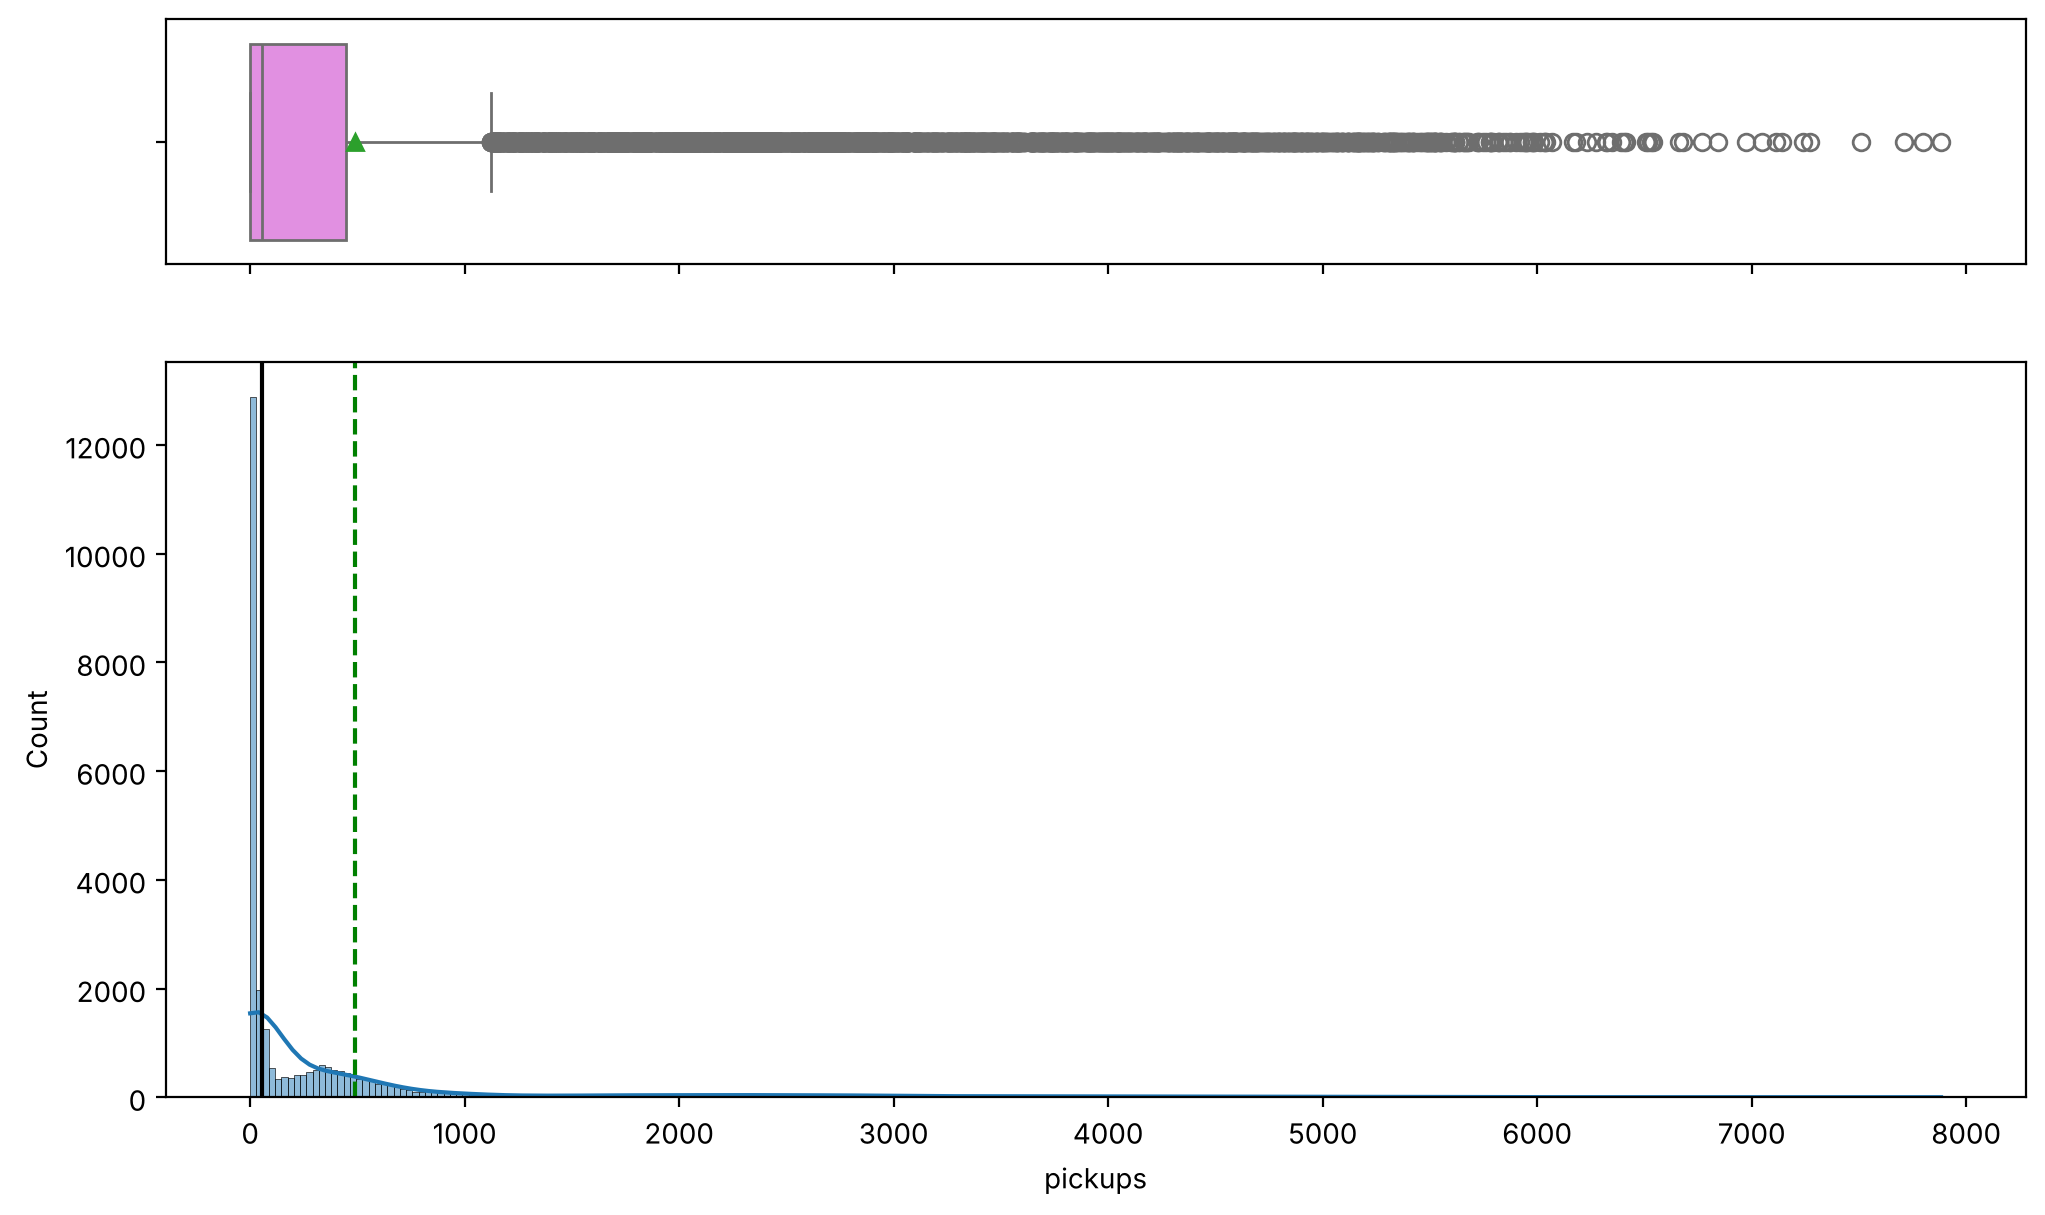

In [16]:


def histogram_boxplot(data, feature, figsize=(12, 7)):
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2, sharex=True, gridspec_kw={"height_ratios": (0.25, 0.75)}, figsize=figsize
    )
    sns.boxplot(x=data[feature], ax=ax_box2, showmeans=True, color="violet")
    sns.histplot(data=data, x=feature, kde=True, ax=ax_hist2)
    ax_hist2.axvline(data[feature].mean(), color="green", linestyle="--")
    ax_hist2.axvline(data[feature].median(), color="black", linestyle="-")
    plt.show()

histogram_boxplot(df, "pickups")

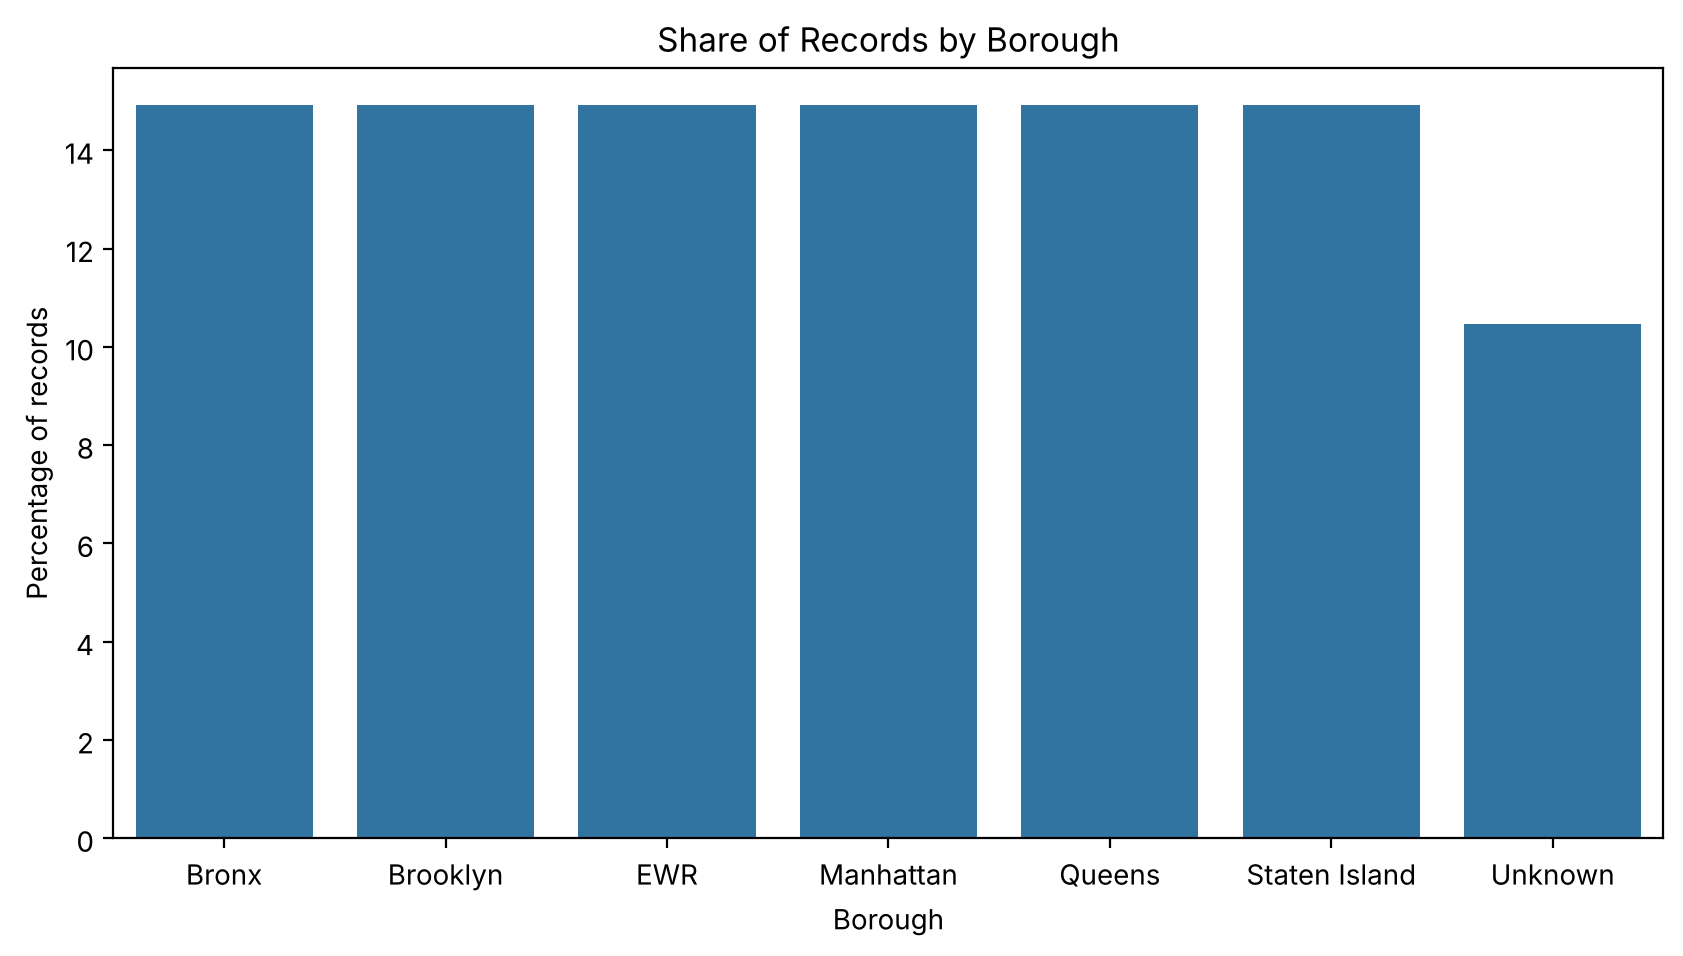

In [17]:
# Bar graph of the percentage of records per borough

plt.figure(figsize=(10, 5))
borough_pct = df["borough"].value_counts(normalize=True) * 100
sns.barplot(x=borough_pct.index, y=borough_pct.values)
plt.ylabel("Percentage of records")
plt.xlabel("Borough")
plt.title("Share of Records by Borough")
plt.show()

### Explanation

- The histogram shows how often different pickup counts occur, while the box plot above it marks the median, the quartiles, and any outliers as individual points. Placing them together makes it easy to connect a spike in the histogram with its position in the box plot.
- The dashed green line marks the mean and the solid black line marks the median. When they are far apart, the distribution is skewed, which is exactly what we see here: a long right tail of very high-pickup hours.
- The bar graph converts `value_counts()` into percentages, showing whether boroughs are represented evenly in the dataset.

**Key takeaway:** Univariate plots describe one variable at a time. A skewed distribution like `pickups` often calls for a log transform later if you plan to model it, and it also tells you the mean alone would be a misleading summary.

**What the data shows.** `pickups` is strongly right-skewed (skewness 3.0): the mean is 490 against a median of 54, with a maximum of 7,883. About 19% of rows have zero pickups, almost all in EWR (4,243 of its 4,343 hours) and Staten Island (1,291 hours); each of the other four boroughs has zero pickups in only 8-9 hours. Each named borough has exactly 4,343 rows (14.9% of records), so the bar chart shows balanced *coverage*, not balanced demand. Because of the skew, any model should be fitted per borough or on a log scale.

# **Topic 6: Bivariate and Multivariate Visualization**

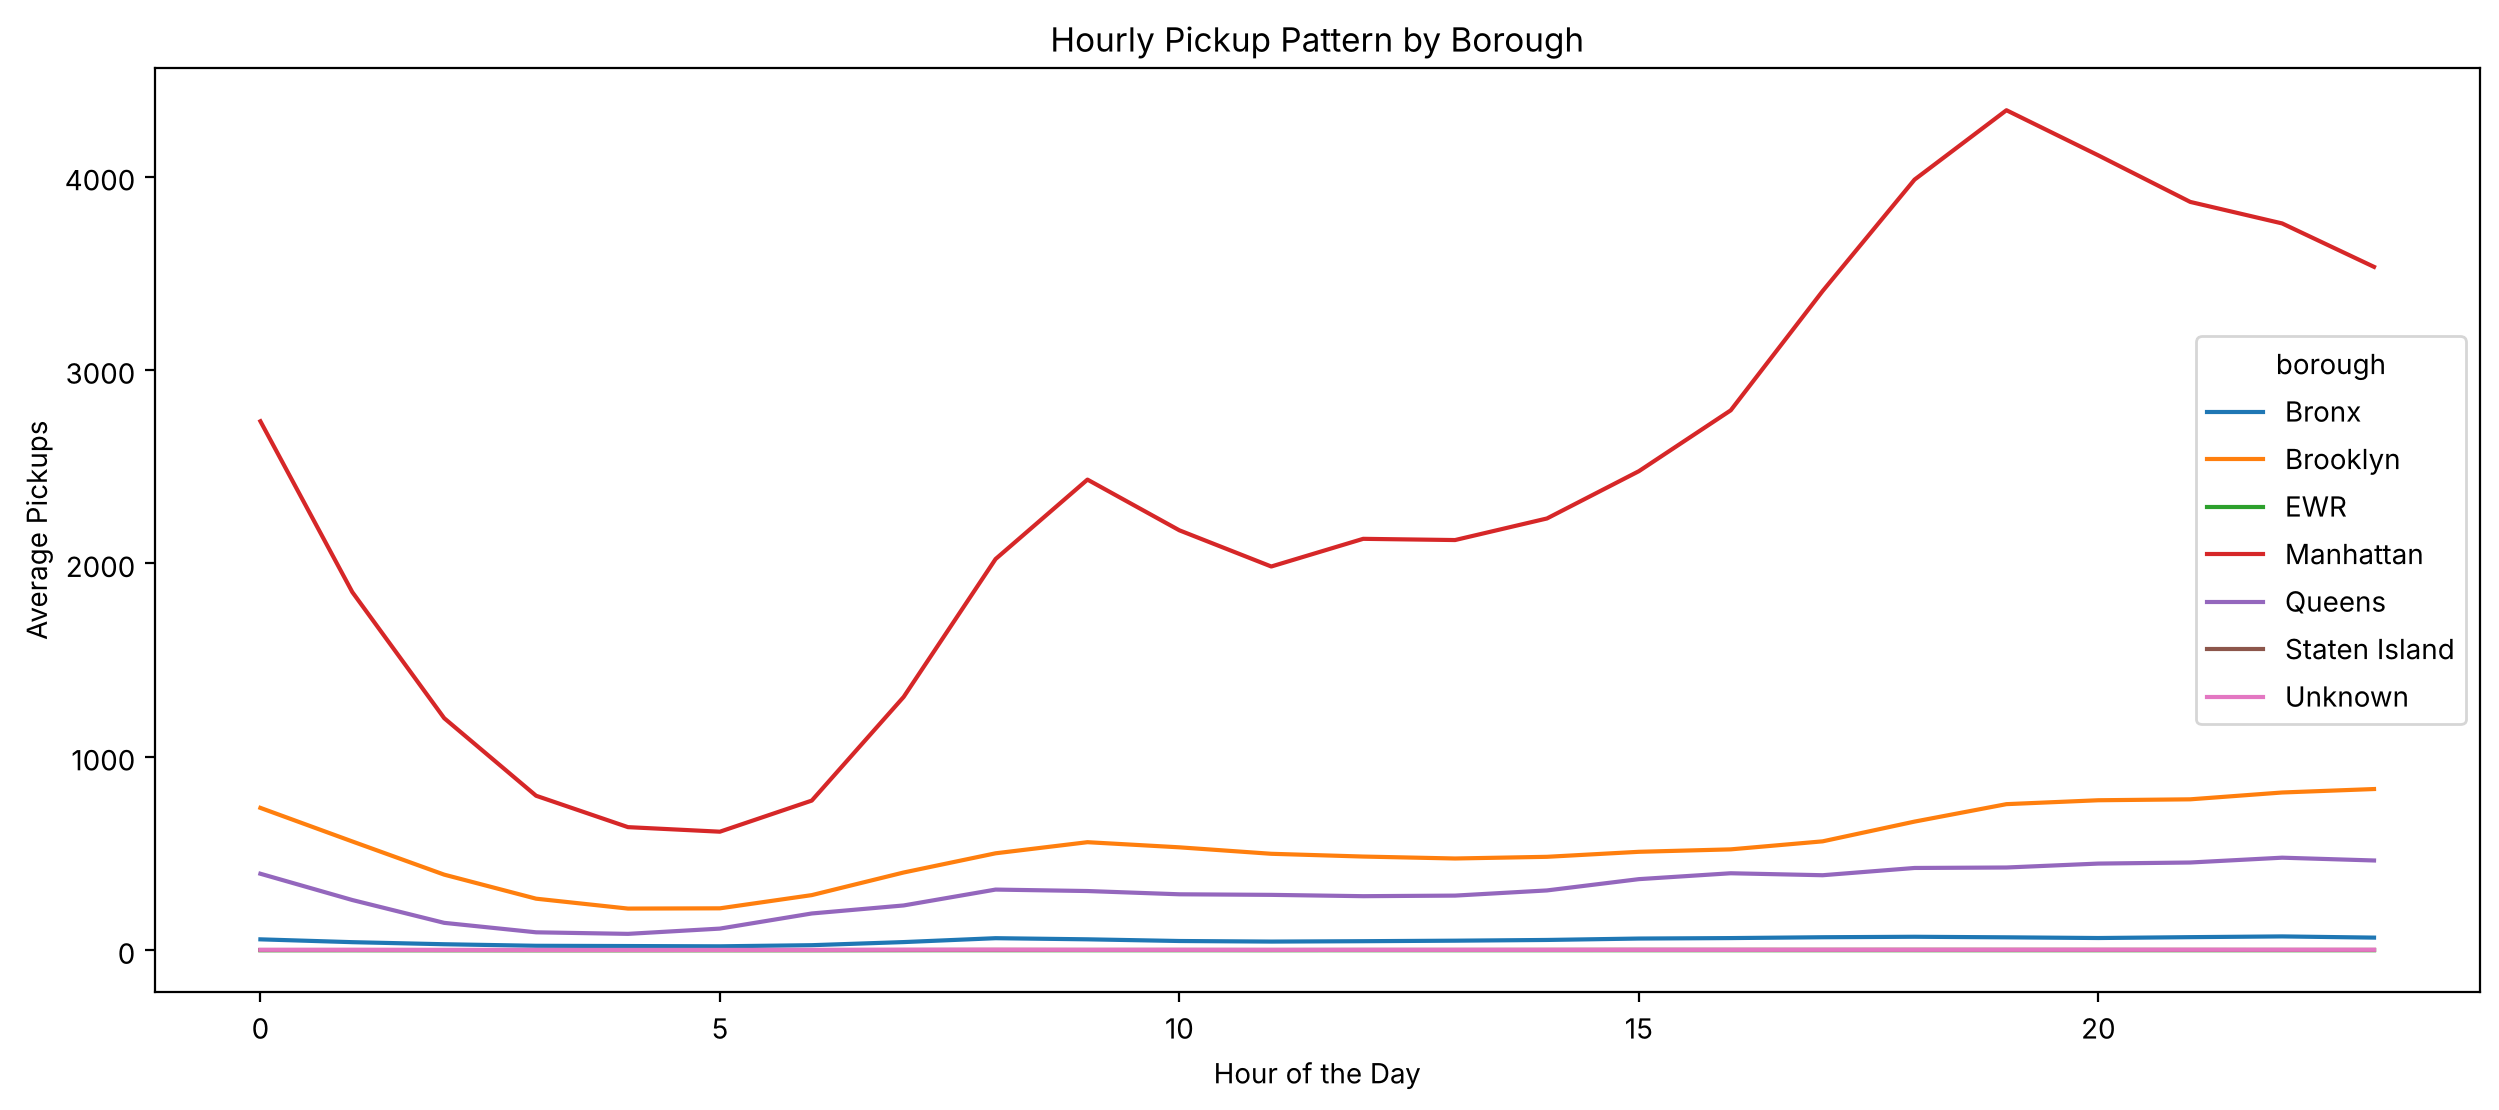

In [18]:
# Pickups across hours of the day, by borough

plt.figure(figsize=(15, 6))
sns.lineplot(x="start_hour", y="pickups", hue="borough", data=df, errorbar=None)
plt.xlabel("Hour of the Day")
plt.ylabel("Average Pickups")
plt.title("Hourly Pickup Pattern by Borough")
plt.show()

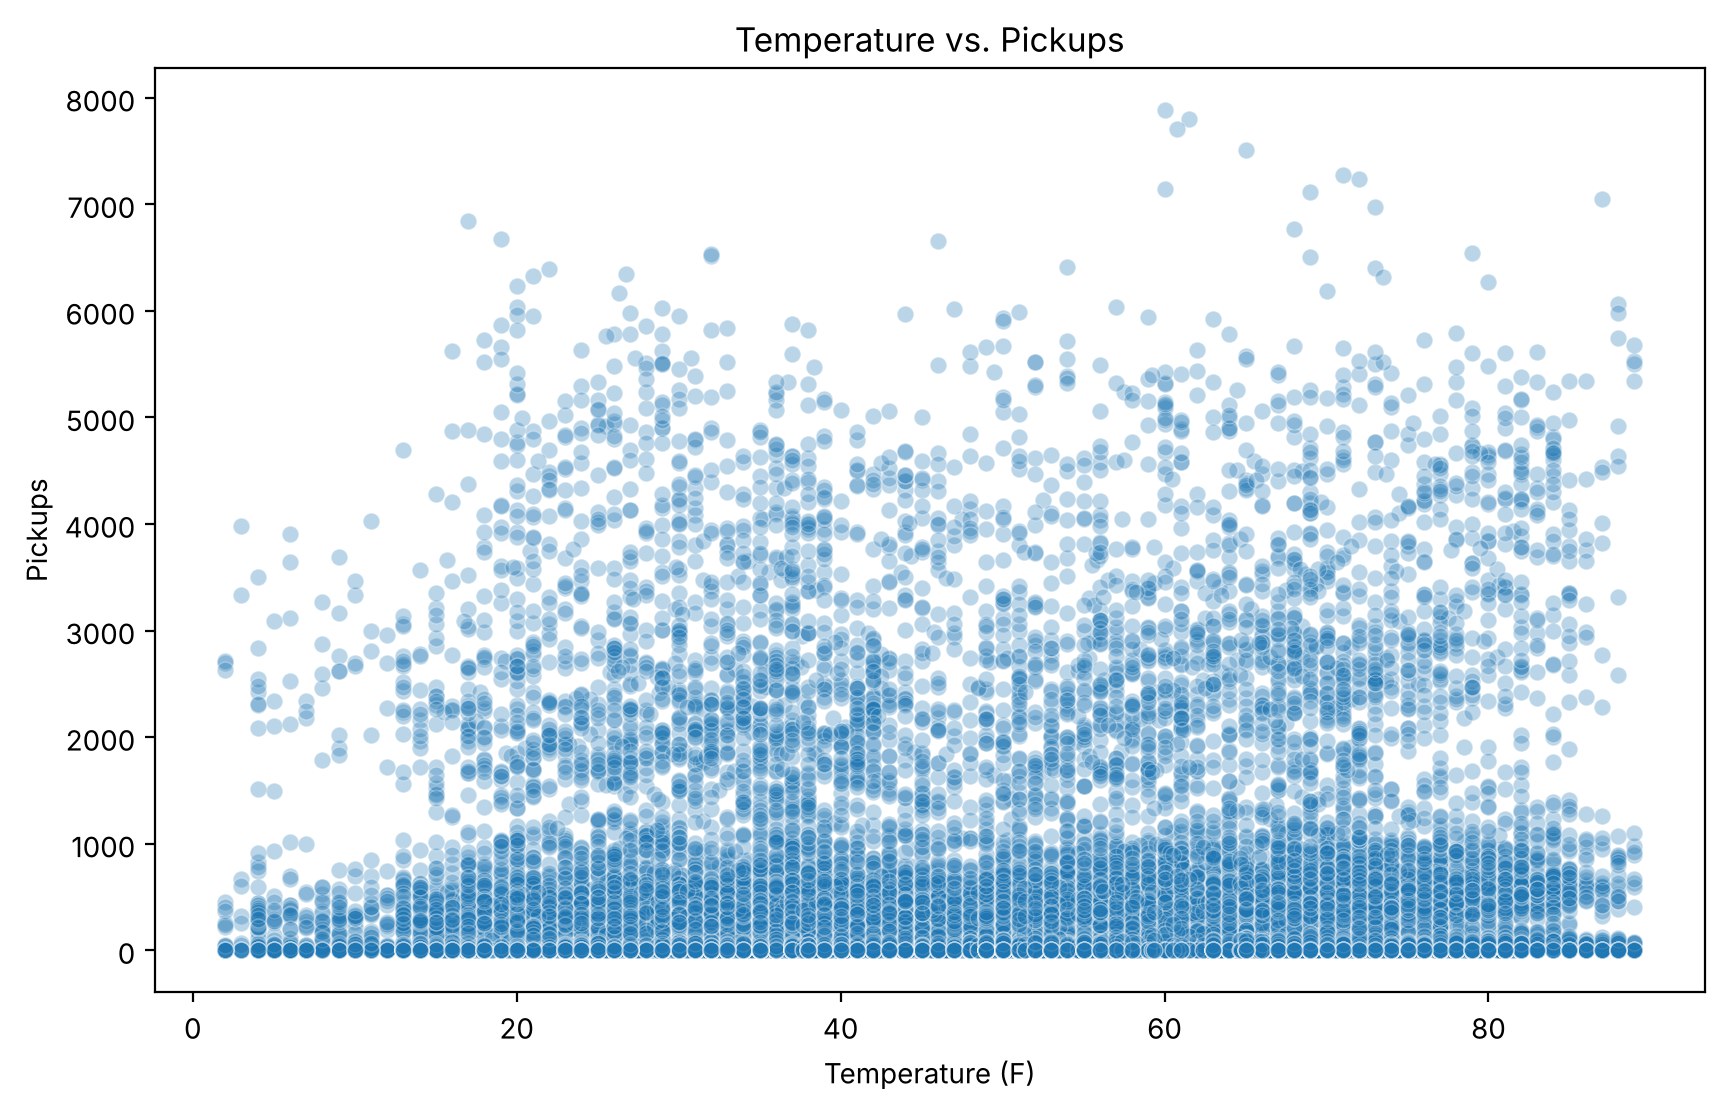

In [19]:
# Temperature vs. pickups

plt.figure(figsize=(10, 6))
sns.scatterplot(x="temp", y="pickups", data=df, alpha=0.3)
plt.xlabel("Temperature (F)")
plt.ylabel("Pickups")
plt.title("Temperature vs. Pickups")
plt.show()

### Explanation

- `sns.lineplot()` with `hue="borough"` draws one line per borough, all on the same axes, so hourly patterns can be compared directly. `errorbar=None` keeps the chart clean by removing the confidence band.
- The scatter plot places every ride as a point, with `temp` on one axis and `pickups` on the other. `alpha=0.3` makes each point partly transparent, so overlapping points show up as darker patches, revealing where most of the data sits.
- Together these are **bivariate** plots: each one shows the relationship between two variables, rather than describing one variable alone.

**Key takeaway:** Line plots are best for a trend over an ordered variable like time. Scatter plots are best for spotting whether two continuous variables move together.

**What the data shows.** Manhattan has a pronounced daily cycle: a smaller morning peak around 09:00 (about 2,434 pickups per hour on average), a dip around midday, then a rise through the afternoon to the main peak at 19:00 (about 4,344), and the lowest demand at 04:00-05:00 (about 600). Brooklyn and Queens show the same overnight dip and a gentle evening rise but a much flatter pattern during the day, and the Bronx is nearly flat. The temperature scatter shows no usable pattern: the correlation between pickups and temperature is 0.05 across all rows and 0.16 within Manhattan, and all other weather variables are even closer to zero.

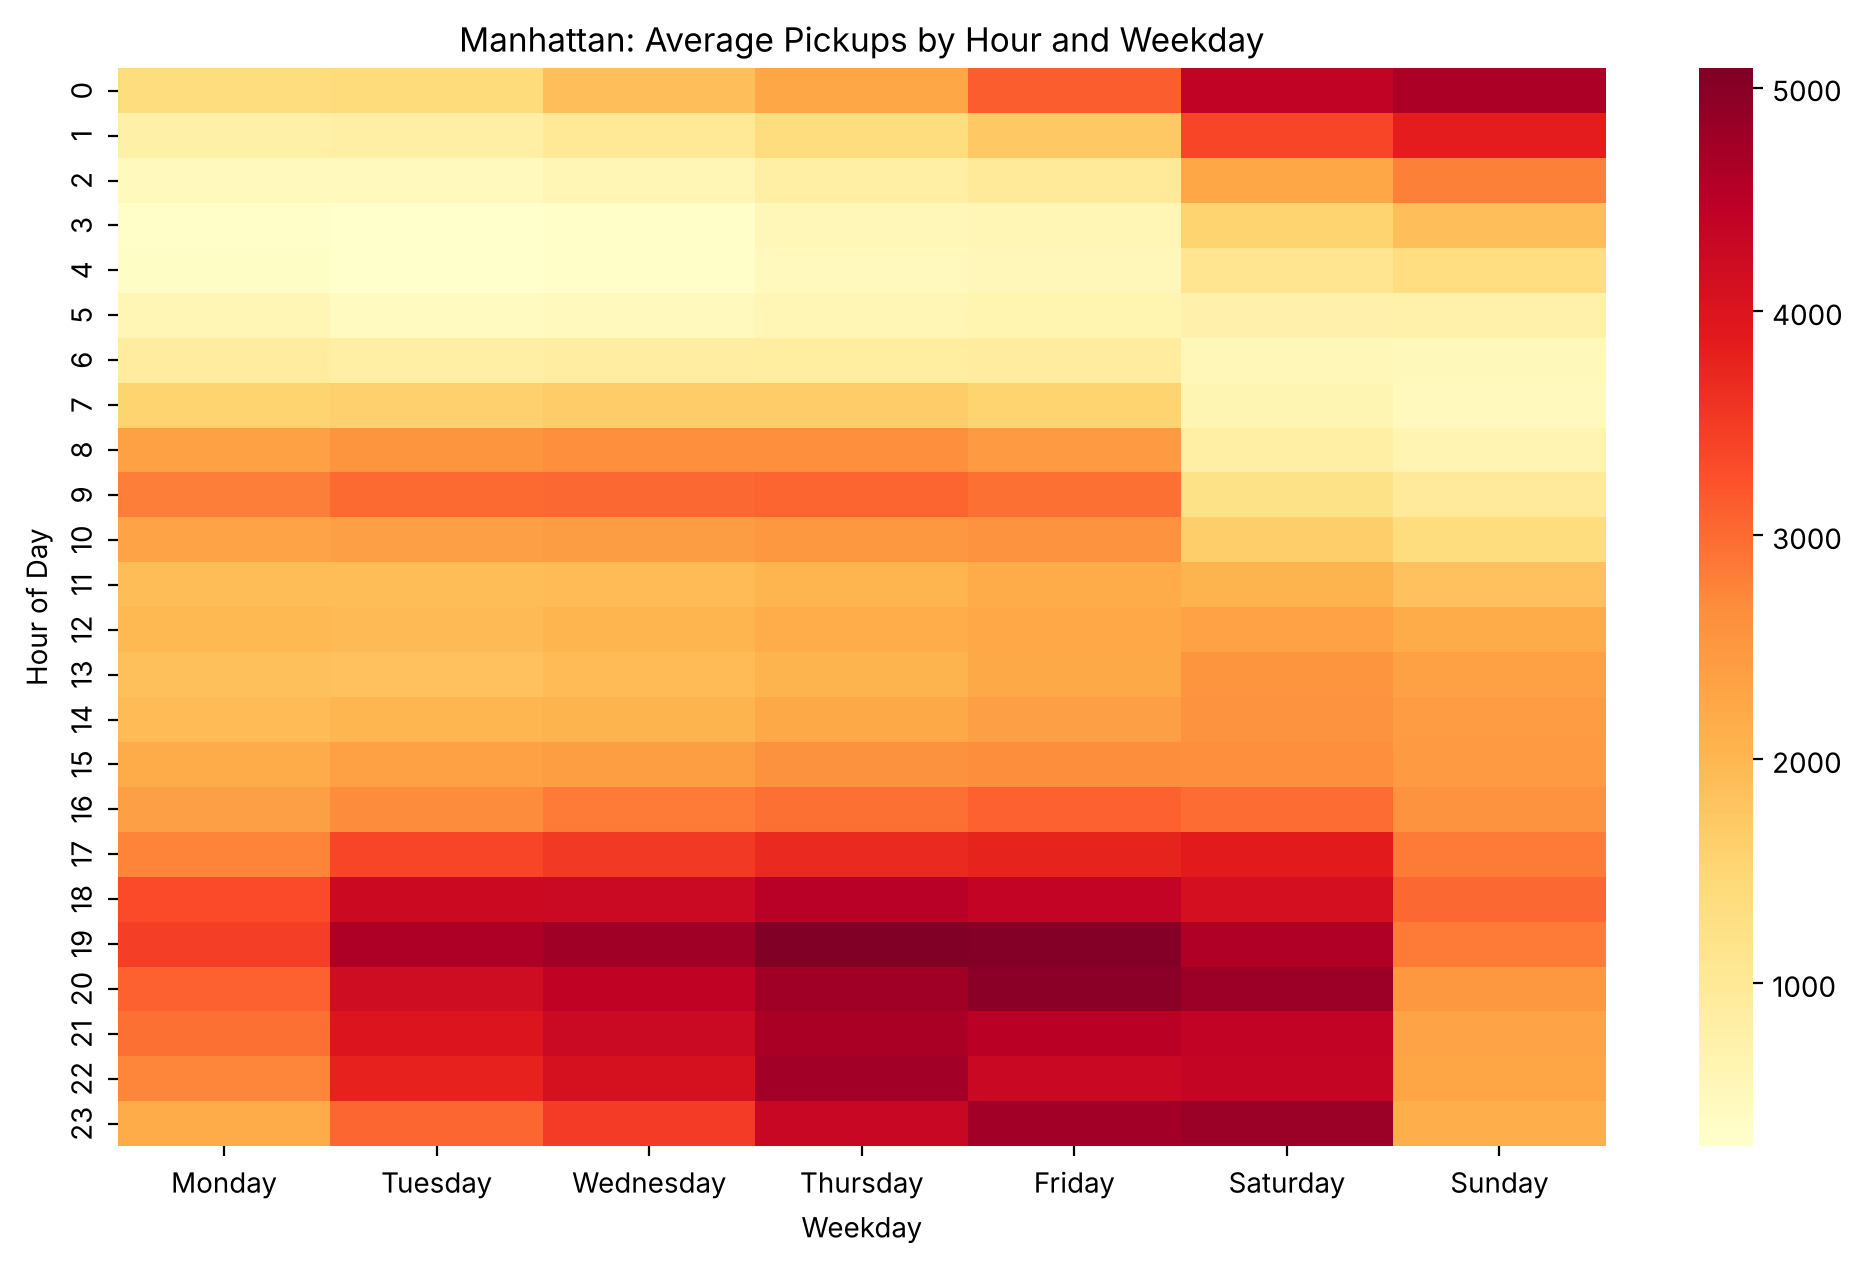

In [20]:
# Heat map: Manhattan pickups by weekday and hour

manhattan = df[df["borough"] == "Manhattan"]

pivot = manhattan.pivot_table(index="start_hour", columns="week_day", values="pickups", aggfunc="mean")

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = pivot[weekday_order]

plt.figure(figsize=(12, 7))
sns.heatmap(pivot, cmap="YlOrRd")
plt.title("Manhattan: Average Pickups by Hour and Weekday")
plt.xlabel("Weekday")
plt.ylabel("Hour of Day")
plt.show()

### Explanation

- `pivot_table()` reshapes the data into a grid: one row per hour, one column per weekday, and each cell holds the average pickups for that combination.
- Reordering the columns with `weekday_order` keeps the days in their natural sequence instead of alphabetical order.
- `sns.heatmap()` colors each cell by its value. Darker or more intense cells mark the busiest hour-and-day combinations, making the peak windows visible at a glance instead of having to scan a table of numbers.

**Key takeaway:** A heat map is the fastest way to spot patterns across two categorical or ordered variables at once. It combines what a line plot and a table would each show separately into a single view.

**What the data shows.** The busiest Manhattan hour-and-weekday cells are Thursday 19:00 (about 5,090 pickups), Friday 19:00 (5,030), Friday 20:00 (4,980), Saturday 23:00 (4,820) and Saturday 20:00 (4,790). By weekday, Friday (2,693), Saturday (2,688) and Thursday (2,611) are busiest and Monday (1,944) is quietest. Weekday evenings and late Friday/Saturday nights are the windows where supply matters most.

# **Topic 7: Which Factors Matter Most? (Quantified)**

The charts suggest that location and time of day dominate. This section measures it: how much of the variation in pickups does each factor explain (R-squared from a regression on that factor), and does weather or the holiday flag add anything once time is accounted for?

In [21]:
import statsmodels.formula.api as smf

manhattan = df[df["borough"] == "Manhattan"].copy()
weather = "spd + vsb + temp + dewp + slp + pcp01 + pcp06 + pcp24 + sd"

def r_squared(data, formula):
    return smf.ols(formula, data).fit().rsquared

rows = [
    ("All boroughs", "Borough only", r_squared(df, "pickups ~ C(borough)")),
    ("All boroughs", "Hour of day only", r_squared(df, "pickups ~ C(start_hour)")),
    ("All boroughs", "Weekday only", r_squared(df, "pickups ~ C(week_day)")),
    ("All boroughs", "Month only", r_squared(df, "pickups ~ C(start_month)")),
    ("All boroughs", "Borough x hour of day", r_squared(df, "pickups ~ C(borough) * C(start_hour)")),
    ("All boroughs", "Borough x hour + weekday + month", r_squared(df, "pickups ~ C(borough) * C(start_hour) + C(week_day) + C(start_month)")),
    ("All boroughs", "... plus all weather variables", r_squared(df, "pickups ~ C(borough) * C(start_hour) + C(week_day) + C(start_month) + " + weather)),
    ("Manhattan only", "Hour of day only", r_squared(manhattan, "pickups ~ C(start_hour)")),
    ("Manhattan only", "Weekday only", r_squared(manhattan, "pickups ~ C(week_day)")),
    ("Manhattan only", "Month only", r_squared(manhattan, "pickups ~ C(start_month)")),
    ("Manhattan only", "Weather variables only", r_squared(manhattan, "pickups ~ " + weather)),
    ("Manhattan only", "Hour + weekday + month", r_squared(manhattan, "pickups ~ C(start_hour) + C(week_day) + C(start_month)")),
    ("Manhattan only", "... plus all weather variables", r_squared(manhattan, "pickups ~ C(start_hour) + C(week_day) + C(start_month) + " + weather)),
]
variance_table = pd.DataFrame(rows, columns=["Scope", "Factors", "R_squared"])
variance_table["R_squared"] = variance_table["R_squared"].round(3)
display(variance_table)

,Scope,Factors,R_squared
0,All boroughs,Borough only,0.673
1,All boroughs,Hour of day only,0.043
2,All boroughs,Weekday only,0.003
3,All boroughs,Month only,0.003
4,All boroughs,Borough x hour of day,0.874
5,All boroughs,Borough x hour + weekday + month,0.881
6,All boroughs,... plus all weather variables,0.881
7,Manhattan only,Hour of day only,0.623
8,Manhattan only,Weekday only,0.036
9,Manhattan only,Month only,0.034


**Answer to "which factor affects pickups the most?"** Location first, then time of day. Borough alone explains **67%** of the variation in pickups, and borough combined with hour of day explains **87%**. Weekday, month and all nine weather variables together add less than one percentage point (88.1%). Within Manhattan, hour of day alone explains **62%**; adding weekday and month raises that to 70%, and weather adds only about 0.5 points (69.6% to 70.1%). A "weather only" model looks better in Manhattan (9%), but most of that is weather proxying for time of day and season.

*Plausible reasons for the dominance of location and hour (not tested in this data):* Manhattan concentrates residents, workers, nightlife and visitors in a small area, and its demand follows commuting and going-out routines.

In [22]:
weather_cols = ["spd", "vsb", "temp", "dewp", "slp", "pcp01", "pcp06", "pcp24", "sd"]
corr_table = pd.DataFrame({
    "All rows": df[weather_cols + ["pickups"]].corr()["pickups"].drop("pickups"),
    "Manhattan only": manhattan[weather_cols + ["pickups"]].corr()["pickups"].drop("pickups"),
}).round(2)
display(corr_table)

# Does rain matter once time of day, weekday and month are controlled? (suggestive only: hourly data are autocorrelated)
manhattan["rain"] = (manhattan["pcp01"] > 0).astype(int)
fit = smf.ols("pickups ~ C(start_hour) + C(week_day) + C(start_month) + rain", manhattan).fit()
print(f"\nHours with measurable rain: {manhattan['rain'].sum()} of {len(manhattan)}")
print(f"Rain coefficient after controlling for hour, weekday and month: {fit.params['rain']:+.0f} pickups per hour "
      f"(Manhattan average: {manhattan['pickups'].mean():,.0f})")

,All rows,Manhattan only
spd,0.01,0.06
vsb,-0.01,-0.04
temp,0.05,0.16
dewp,0.03,0.08
slp,-0.02,-0.05
pcp01,0.00,0.02
pcp06,-0.00,-0.02
pcp24,-0.02,-0.07
sd,-0.01,0.00



Hours with measurable rain: 394 of 4343
Rain coefficient after controlling for hour, weekday and month: +214 pickups per hour (Manhattan average: 2,387)


**Weather.** No weather variable has a correlation above 0.16 with pickups. After controlling for hour, weekday and month, hours with measurable rain in Manhattan show about **214 more pickups per hour** (roughly 9% above the Manhattan average). This is suggestive of a rain uplift, but hourly observations are not independent, so it is not a formal test and should be validated on more data.

In [23]:
def holiday_vs_baseline(borough):
    x = df[df["borough"] == borough]
    daily = (x.assign(date=x["pickup_dt"].dt.date)
               .groupby(["date", "week_day"])
               .agg(total=("pickups", "sum"), hours=("pickups", "size"), hday=("hday", "max"))
               .reset_index())
    daily = daily[daily["hours"] >= 23]  # keep (almost) complete days
    baseline = daily[daily["hday"] == "N"].groupby("week_day")["total"].mean()  # average non-holiday day, same weekday
    hol = daily[daily["hday"] == "Y"].copy()
    hol["pct_vs_same_weekday"] = ((hol["total"] / hol["week_day"].map(baseline) - 1) * 100).round(0)
    return hol.set_index("date")[["week_day", "pct_vs_same_weekday"]]

holiday_table = pd.concat({b: holiday_vs_baseline(b)["pct_vs_same_weekday"] for b in ["Manhattan", "Brooklyn", "Queens"]}, axis=1)
holiday_table.insert(0, "weekday", holiday_vs_baseline("Manhattan")["week_day"])
print("Holiday-flagged days: % difference in daily pickups vs. the average non-holiday day with the same weekday")
display(holiday_table)

Holiday-flagged days: % difference in daily pickups vs. the average non-holiday day with the same weekday


,weekday,Manhattan,Brooklyn,Queens
date,,,,
2015-01-01,Thursday,-44.0,10.0,-29.0
2015-01-19,Monday,-32.0,-15.0,-20.0
2015-02-12,Thursday,3.0,-7.0,-10.0
2015-02-16,Monday,16.0,10.0,6.0
2015-05-10,Sunday,1.0,19.0,17.0
2015-05-25,Monday,-27.0,41.0,33.0
2015-06-03,Wednesday,13.0,24.0,24.0


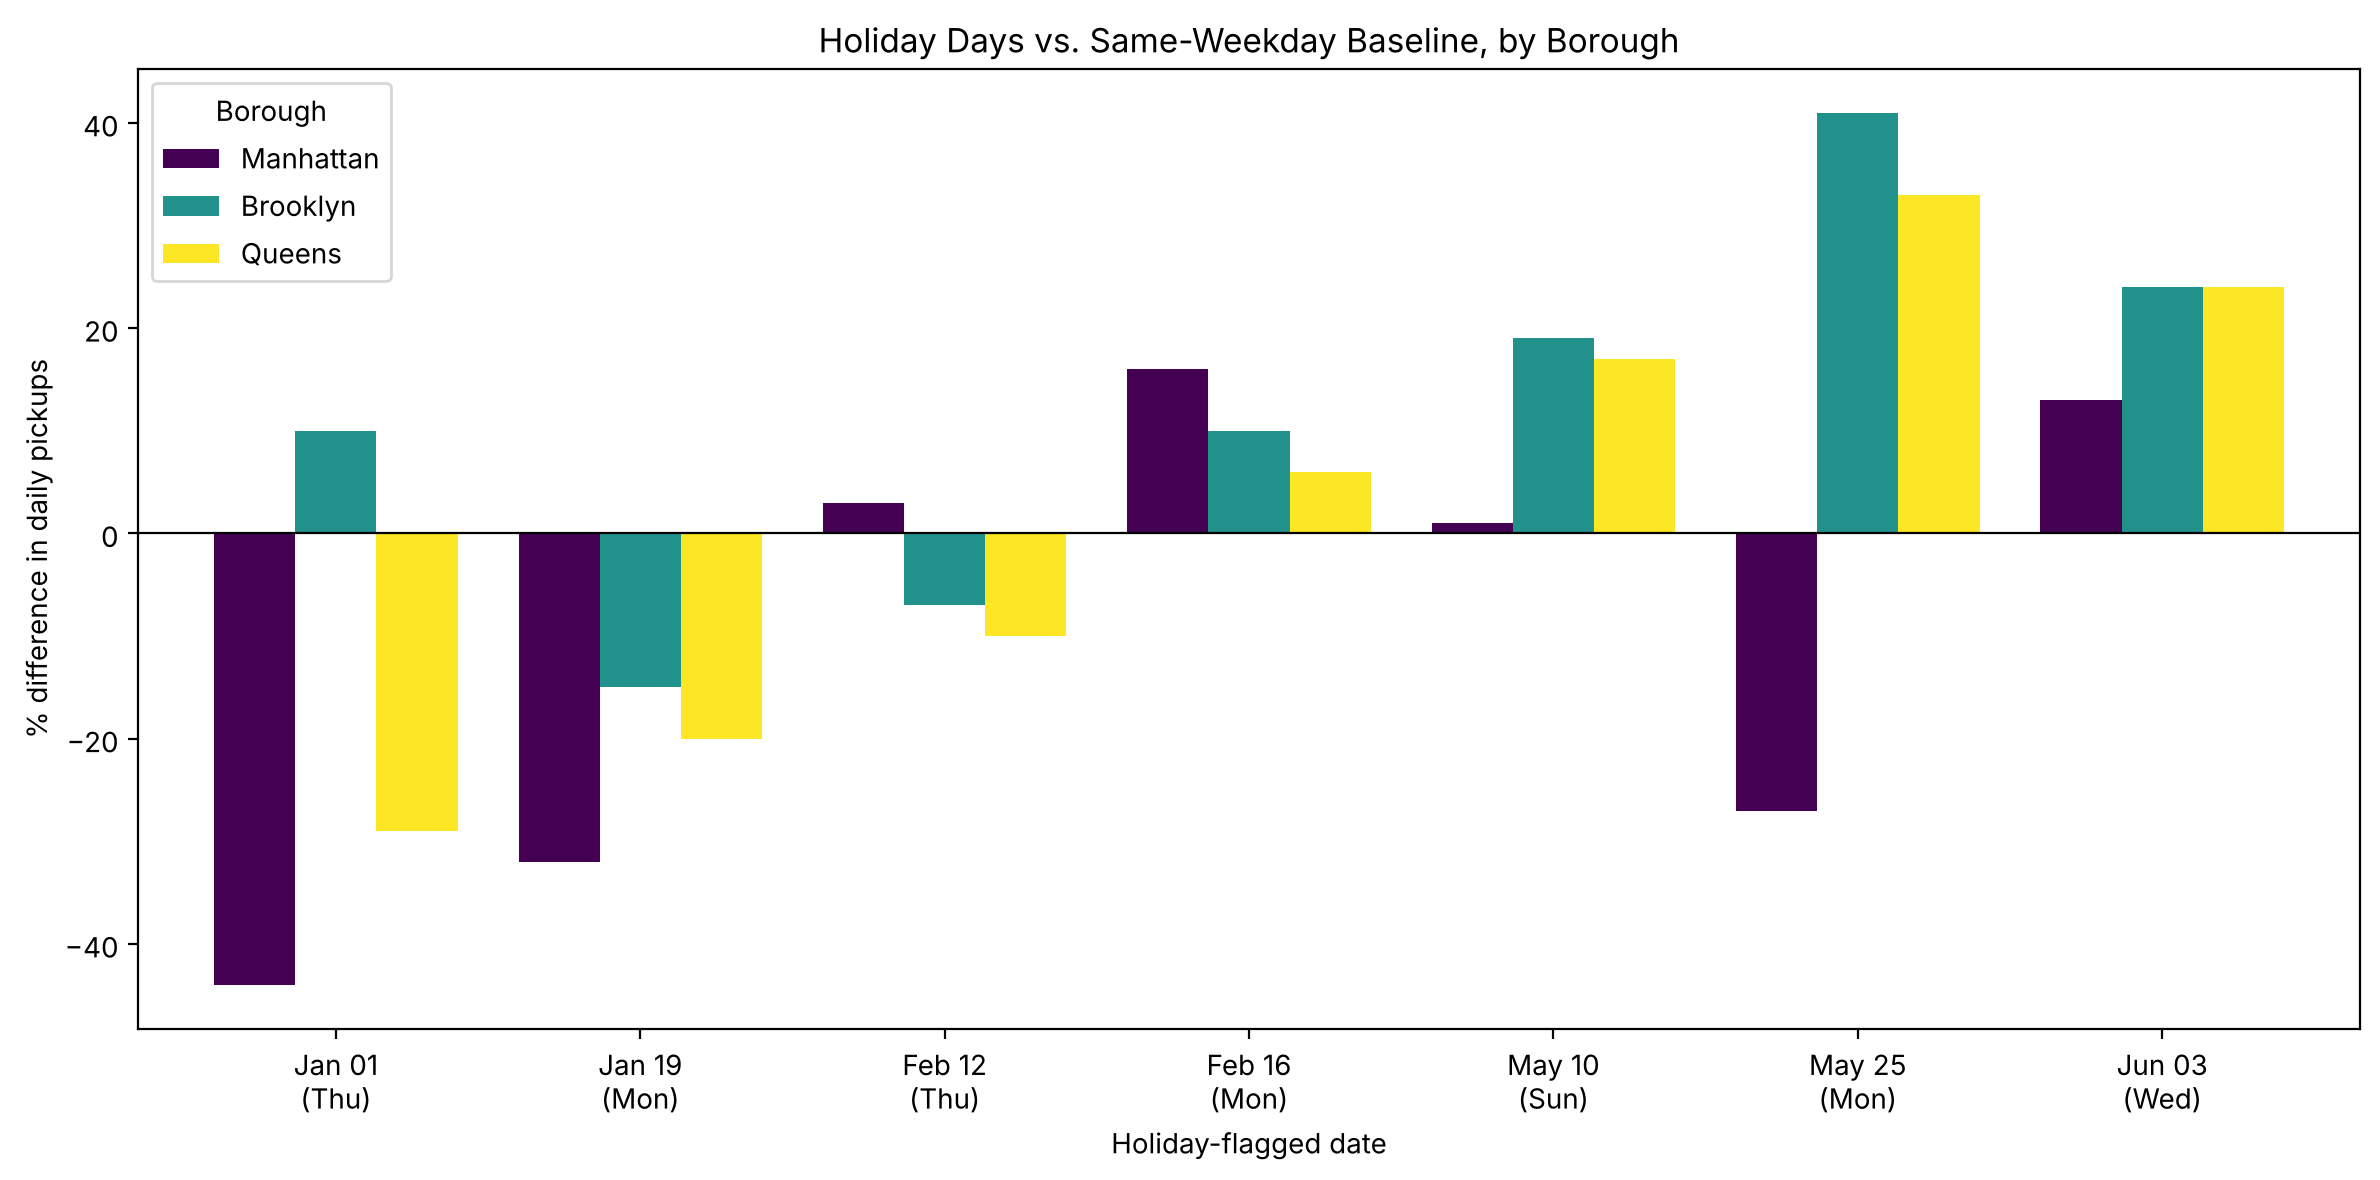

In [24]:
plot_data = holiday_table.drop(columns="weekday").copy()
plot_data.index = [f"{d:%b %d}\n({w[:3]})" for d, w in zip(holiday_table.index, holiday_table["weekday"])]
ax = plot_data.plot(kind="bar", figsize=(12, 6), width=0.8, colormap="viridis")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Holiday Days vs. Same-Weekday Baseline, by Borough")
ax.set_ylabel("% difference in daily pickups")
ax.set_xlabel("Holiday-flagged date")
plt.xticks(rotation=0)
plt.legend(title="Borough", loc="upper left")
plt.tight_layout()
plt.show()

**Holidays.** Only **7 distinct days** carry the holiday flag (Jan 1, Jan 19, Feb 12, Feb 16, May 10, May 25 and Jun 3), and three of them are Mondays, the quietest weekday, so a raw holiday-vs-non-holiday average mixes the holiday effect with a weekday effect. Compared with the average non-holiday day of the same weekday, Manhattan demand fell sharply on **Jan 1 (-44%), Jan 19 (-32%) and May 25 (-27%)**, but was flat or higher on the other four days (+1% to +16%). On May 25, Manhattan fell 27% while Brooklyn rose 41% and Queens 33%. So the overall Manhattan holiday drop of about 15% is driven by three days, and the holiday effect is inconsistent across holidays and boroughs. Seven days are too few for a reliable statistical test.

In [25]:
monthly = manhattan.groupby(manhattan["pickup_dt"].dt.month)["pickups"].mean().round(0)
monthly.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
display(monthly.to_frame("Avg Manhattan pickups per hour").T)

,Jan,Feb,Mar,Apr,May,Jun
Avg Manhattan pickups per hour,1959.0,2557.0,2233.0,2289.0,2539.0,2771.0


**Trend over the six months.** Average Manhattan pickups per hour rose from 1,959 in January to 2,771 in June (+41%), though not steadily (March is below February). With only six months of data, a growth trend cannot be separated from seasonality.

# **Summary of Findings, Recommendations and Limitations**

## Answers to the guiding questions

1. **What variables influence pickups?** Borough (location) and hour of day are by far the strongest. Weekday and month matter a little. Weather variables and the holiday flag add very little once time is accounted for.
2. **Which factor affects pickups the most, and why?** Location: borough alone explains 67% of the variation, and borough with hour of day 87%. Manhattan accounts for about 73% of all pickups. Plausible reasons (not testable with this data): density of residents, workers and nightlife, and routine commuting and going-out patterns.
3. **Recommendations:** see below.

## Key findings

- **Manhattan dominates demand** (2,387 pickups per hour on average, about 73% of all pickups); EWR and Staten Island are near zero.
- **Time of day is the main driver within a borough:** Manhattan peaks at 19:00 (about 4,300) and bottoms out at 04:00-05:00 (about 600). The busiest cells are Thursday and Friday around 19:00-20:00 and Saturday evening and late night.
- **Weather has a weak effect:** correlations are 0.16 or less, and weather adds about 0.5 points of explained variance in Manhattan once time is controlled. Rain hours show a suggestive uplift of about 9%.
- **Holidays are inconsistent:** the overall Manhattan holiday drop (about -15%) is driven by three of seven flagged days; the other four were flat or higher, and boroughs behave differently (on May 25, Manhattan -27%, Brooklyn +41%, Queens +33%).
- **Demand grew from January to June** (Manhattan +41%), but six months cannot separate trend from seasonality.

## Recommendations for Uber management

1. **Position supply in Manhattan for the evening peak:** concentrate driver availability and incentives at 18:00-22:00, especially Thursday and Friday, plus Saturday night.
2. **Use the hour x weekday view for incentive planning:** target windows where demand is high and supply is likely short, and avoid paying for supply in the 03:00-06:00 trough.
3. **Do not apply a blanket holiday policy:** effects differ by holiday and by borough. Build holiday-specific forecasts once there is more holiday history.
4. **Treat weather as a secondary signal:** test rain as an uplift flag in a forecasting model rather than building weather-driven staffing rules.
5. **Review EWR and Staten Island coverage:** EWR has zero pickups in 4,243 of 4,343 hours and Staten Island in 1,291, which suggests minimal service or incomplete data in 2015.
6. **Next step:** fit a demand forecasting model (for example gradient boosting) with borough, hour, weekday, holiday, weather and lagged pickups, using at least a full year of data.

## Limitations

- **Six months of data (January-June 2015):** seasonality across a full year cannot be assessed, and only 7 holiday days are flagged.
- **Hourly data are autocorrelated:** significance tests treating each hour as independent would be misleading, so effects are described rather than tested.
- **Unknown borough:** 3,043 rows have no borough label; they carry under 0.1% of pickups, but the cause of the missing labels is unconfirmed.
- **Demand only:** there is no driver-supply, wait-time or price data, so the recommendations assume supply can follow demand.
- **Descriptive analysis:** associations, not causal effects.